In [1]:
# @@ENV@@ — Keras backend, visible GPU and global seed
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


import kagglesdk.kaggle_env as kaggle_env

if not hasattr(kaggle_env, "get_web_endpoint"):
    kaggle_env.get_web_endpoint = kaggle_env.get_endpoint

import kagglehub
import keras
import keras_cv

print("GPUs:", gpus)

2026-09-25 10:01:28.634435: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1790323288.646937  722032 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1790323288.650764  722032 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### **Setup**

In [2]:
# @@CFG@@ — the knobs the post-hoc needs; split and sampling live in the frozen frames
class CFG:
    seed = 53
    image_size = (256, 256)
    batch_size = 64
    num_classes = 1
    xai_balance = "equal"   # half per class: the sample of the study
    xai_n = None            # largest balanced sample allowed by the frozen split
    shape_top_k = 2         # raw features selected for stability and SHAP-LORE agreement
    shape_top_k = 2
keras.utils.set_random_seed(CFG.seed)

In [3]:
# @@LIBS@@ - Common libraries used across the post-hoc pipeline.
import glob, gc, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

In [4]:
# @@PATHS@@ — dataset, variant and row identity are declared HERE; every path derives from them
import sys

BASE_PATH = os.environ.get("DUM_BASE", os.environ.get("ISIC24_BASE", "/mnt/disk1/home/cgiovannoni/mod-attendance"))
sys.path.insert(0, os.path.join(BASE_PATH, "src")) if os.path.join(BASE_PATH, "src") not in sys.path else None

from isic24 import paths as pth
from isic24 import xai_subset as xs

pth.DATASET, pth.VARIANT = "brset", "plain"   # BRSET/Symile: change these two, nothing else
xs.ID_COL = "image_id"                             # row identity column of this dataset

DATA_DIR = str(pth.data_dir())                    # images (hdf5) live at dataset level
DATA_PATH = str(pth.data_path())                  # metadata of this variant
ART_PATH = str(pth.art_path())
FEATURE_SPACE_PATH = os.path.join(ART_PATH, "feature_space")
RUNS_PATH = os.path.join(ART_PATH, "runs")
SUMMARIES_PATH = os.path.join(ART_PATH, "summaries")

TRAIN_META = os.path.join(DATA_PATH, "train-metadata.parquet")
TEST_META = os.path.join(DATA_PATH, "test-metadata.parquet")
TRAIN_HDF5 = os.path.join(DATA_DIR, "train-image.hdf5")
TEST_HDF5 = os.path.join(DATA_DIR, "test-image.hdf5")

print(f"dataset={pth.DATASET}/{pth.VARIANT} | id={xs.ID_COL}\n  data {DATA_PATH}\n  art  {ART_PATH}")

dataset=brset/plain | id=image_id
  data /mnt/disk1/home/cgiovannoni/mod-attendance/data/brset/plain
  art  /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain


In [5]:
# @@FRAMES@@ — load the frames the training froze; this notebook never rebuilds the split
import json as _json
import pandas as pd

validation_df = pd.read_parquet(os.path.join(ART_PATH, "evaluation_frame.parquet"))
training_df = pd.read_parquet(os.path.join(ART_PATH, "training_frame.parquet"))

_snap = _json.load(open(os.path.join(ART_PATH, "validation_snapshot.json")))
_live = [str(v) for v in xs.row_ids(validation_df)]
_frozen = [str(v) for v in _snap["row_ids"]]
if _live != _frozen:
    _lost, _new = set(_frozen) - set(_live), set(_live) - set(_frozen)
    raise RuntimeError(
        f"[FRAMES] the evaluation frame ({len(_live)} rows) is not the frozen validation "
        f"({len(_frozen)} rows): "
        + ("the same rows in a DIFFERENT ORDER." if not (_lost or _new)
           else f"{len(_lost)} missing, {len(_new)} new.")
        + " Every val_index in the XAI artifacts is a position into the frozen frame.")

print(f"[FRAMES] evaluation {validation_df.shape}, {int(validation_df.target.sum())} positive, "
      f"prevalence {validation_df.target.mean():.4f} | training {training_df.shape}")

[FRAMES] evaluation (90, 35), 30 positive, prevalence 0.3333 | training (10271, 35)


In [6]:
# @@CUSTOM_LAYERS@@ — register the shared Keras layers, so load_model needs no custom_objects
import sys, os
_src = os.path.join(BASE_PATH, "src")
if _src not in sys.path:
    sys.path.insert(0, _src)

from isic24.mod_attendance import (
    ConstantScale, ScalarMultiply, LearnableAlpha, FusionWithGamma, GateEntropyLoss)

In [7]:
# @@PARAMETERS@@ — canonical study dirs, budgets and the run selection of the loops below
CANONICAL = {
    "vanilla":             os.path.join(RUNS_PATH, "vanilla", "20260909-150705"),
    "fixed_scaling":       os.path.join(RUNS_PATH, "fixed_scaling", "20260914-094615"),
    "learnable_scaling":   os.path.join(RUNS_PATH, "learnable_scaling", "20260909-183931"),
    "loss_regularization": os.path.join(RUNS_PATH, "loss_regularization", "20260910-104319"),
    "controlled_fusion":   os.path.join(RUNS_PATH, "controlled_fusion", "20260911-103310"),
    "adaptive_gating":     os.path.join(RUNS_PATH, "adaptive_gating", "20260914-235654"),
}

N_CANONICAL_RUNS = 132
_runs = {i: sorted(glob.glob(os.path.join(d, "*", "*", "config.json"))) for i, d in CANONICAL.items()}
_configs = {c: json.load(open(c)) for cs in _runs.values() for c in cs}
_spaces = {c: cfg.get("feature_space_file") for c, cfg in _configs.items()}
_space_fps = {c: cfg.get("feature_space_fingerprint") for c, cfg in _configs.items()}
for _i, _cs in _runs.items():
    print(f"  {_i:>19} {os.path.basename(CANONICAL[_i]):<16} {len(_cs):>3} runs  {{{_cs and _spaces[_cs[0]]}}}")

assert (sum(map(len, _runs.values())) == N_CANONICAL_RUNS
        and None not in _spaces.values() and None not in _space_fps.values()
        and len(set(_space_fps.values())) == 1), (
    "not 132 runs with one FeatureSpace fingerprint: read the lines above")

cf_study_dir = CANONICAL["controlled_fusion"]   # gamma sweep writes here
ag_study_dir = CANONICAL["adaptive_gating"]     # gate diagnostics write here

FAITH_BUDGETS = (0.05, 0.10, 0.20, 0.40, 0.60)   # q points the model is re-scored at (GPU)
Q_MAX_REPORT = [0.20, 0.60]                      # integration cutoffs, re-read from saved curves

FAITH_ONLY_IMPL = None    # e.g. ["vanilla", "adaptive_gating"]; None = every canonical family
FAITH_MAX_RUNS  = None    # e.g. 5 for a smoke test
FAITH_OVERWRITE = False   # True = recompute and overwrite the curves a run already holds
FAITH_DRY_RUN   = False   # True = list what would run, load no models

cf_combined = pd.read_csv(os.path.join(cf_study_dir, "combined_summary.csv"))
ag_combined = pd.read_csv(os.path.join(ag_study_dir, "combined_summary.csv"))
for _summary in (cf_combined, ag_combined):
    _summary.columns = _summary.columns.str.strip()
    for _column in _summary.select_dtypes(include=["object", "string"]):
        _summary[_column] = _summary[_column].str.strip()
print(f"canonical {len(CANONICAL)} families | cf_combined {cf_combined.shape} | ag_combined {ag_combined.shape}")

              vanilla 20260909-150705    6 runs  {feature_space/20260909-150500/feature_space.keras}
        fixed_scaling 20260914-094615   54 runs  {feature_space/20260914-094546/feature_space.keras}
    learnable_scaling 20260909-183931   30 runs  {feature_space/20260909-183527/feature_space.keras}
  loss_regularization 20260910-104319   30 runs  {feature_space/20260910-151138/feature_space.keras}
    controlled_fusion 20260911-103310    6 runs  {feature_space/20260911-103226/feature_space.keras}
      adaptive_gating 20260914-235654    6 runs  {feature_space/20260914-235642/feature_space.keras}
canonical 6 families | cf_combined (6, 20) | ag_combined (6, 19)


In [8]:
# @@HDF5@@ — the image store the evaluation frame reads from
import h5py

training_validation_hdf5 = h5py.File(TRAIN_HDF5, 'r')

In [9]:
# @@FEATURE_SPACE@@ — the space the checkpoints were trained with; the feature spec comes from it
from isic24.xai_driver import feature_space_fingerprint

FEATURE_SPACE_FILE = next(iter(_spaces.values()))
feature_space = keras.saving.load_model(os.path.join(ART_PATH, FEATURE_SPACE_FILE))
assert isinstance(feature_space, keras.utils.FeatureSpace), (
    f"{FEATURE_SPACE_FILE} deserializes to {type(feature_space).__name__}, not a FeatureSpace")

feature_order = list(feature_space.features)   # raw feature order; encoded columns use their own order
FEAT_COLS = feature_order

ENCODED_DIM, FEATURE_SPACE_FP = feature_space_fingerprint(feature_space)
assert FEATURE_SPACE_FP == next(iter(set(_space_fps.values()))), (
    "the loaded FeatureSpace does not match the canonical runs")

_missing = [c for c in FEAT_COLS if c not in validation_df.columns]
assert not _missing, f"the frozen frames do not carry {len(_missing)} model features: {_missing}"
print(f"FeatureSpace {FEATURE_SPACE_FILE} | {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims"
      f" | adapt fp {FEATURE_SPACE_FP[:16]}")

FeatureSpace feature_space/20260909-150500/feature_space.keras | 6 features -> 175 encoded dims | adapt fp e2ac7ea2b9967d31


I0000 00:00:1790323292.195780  722032 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22800 MB memory:  -> device: 0, name: Quadro RTX 6000, pci bus id: 0000:17:00.0, compute capability: 7.5


In [10]:
# @@DATASET_BUILDERS@@ — decoder and dataset builder; the post-hoc never shuffles nor augments
from tqdm import tqdm

def build_decoder(with_labels=True, target_size=CFG.image_size):
    def decode_image(inp):
        image = tf.io.decode_jpeg(inp["images"])
        image = tf.image.resize(image, size=target_size, method="area")
        image = tf.cast(image, tf.float32) / 255.0
        image = tf.reshape(image, [*target_size, 3])
        return {"images": image, "features": inp["features"]}

    def decode_with_labels(inp, label):
        label = tf.reshape(tf.cast(label, tf.float32), [CFG.num_classes])
        return decode_image(inp), label

    return decode_with_labels if with_labels else decode_image


def build_dataset(row_ids, hdf5, features, labels=None, batch_size=None, cache=True):
    images = [hdf5[row_id][()] for row_id in tqdm(row_ids, desc="Loading images")]
    inputs = {"images": images, "features": features}
    slices = (inputs, labels) if labels is not None else inputs

    ds = tf.data.Dataset.from_tensor_slices(slices)
    ds = ds.map(build_decoder(labels is not None), num_parallel_calls=tf.data.AUTOTUNE,
                deterministic=True)
    if cache:
        ds = ds.cache()
    if batch_size is not None:
        ds = ds.batch(batch_size)
    return ds


def _to_feature_dict(df):
    feat_dict = {}
    for col in df.columns:
        series = df[col]
        feat_dict[col] = (series.to_numpy() if pd.api.types.is_numeric_dtype(series.dtype)
                          else series.astype(str).to_numpy())
    return feat_dict

In [11]:
# @@BUILD_DATASETS@@ — the evaluation set, decoded once and encoded in frame order
validation_ds = build_dataset(
    xs.row_ids(validation_df), training_validation_hdf5,
    _to_feature_dict(validation_df[FEAT_COLS]), validation_df.target.to_numpy(),
    batch_size=CFG.batch_size,
).map(lambda x, y: ({"images": x["images"], "features": feature_space(x["features"])}, y),
      num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).prefetch(tf.data.AUTOTUNE)

_labels = np.concatenate([np.asarray(y).reshape(-1) for _, y in validation_ds])
assert np.array_equal(_labels, validation_df.target.to_numpy()), (
    f"the dataset yields {len(_labels)} rows against the frame's {len(validation_df)}, or the same "
    f"rows in another order: every val_index is a position into the frame")
print(f"[EVAL] {len(_labels)} rows in frame order, {len(FEAT_COLS)} features -> {ENCODED_DIM} encoded dims")

Loading images: 100%|██████████| 90/90 [00:00<00:00, 2306.86it/s]


[EVAL] 90 rows in frame order, 6 features -> 175 encoded dims


In [12]:
# @@ENCODED_NAMES@@ — names of the encoded columns in FeatureSpace order
from keras.layers import StringLookup, Discretization, Normalization

encoded_feature_names = []
feature_dim_sizes = {}

for name in sorted(feature_space.features):
    preproc = feature_space.preprocessors[name]

    # 1) Categorical features: StringLookup → one-hot of size vocabulary_size
    if isinstance(preproc, StringLookup):
        vocab = preproc.get_vocabulary()
        # each token gets its own encoded dim
        for token in vocab:
            encoded_feature_names.append(f"{name}__{token}")
        d = len(vocab)

    # 2) Discretized float (age_approx): Discretization → one-hot over bins
    elif isinstance(preproc, Discretization):
        boundaries = preproc.get_config().get("bin_boundaries", [])
        n_bins = len(boundaries) + 1
        for b in range(n_bins):
            encoded_feature_names.append(f"{name}_bin_{b}")
        d = n_bins

    # 3) Normalized numeric or raw float: 1 dim
    elif isinstance(preproc, Normalization):
        encoded_feature_names.append(name)
        d = 1

    else:
        # "float" (already normalized) or any other scalar
        encoded_feature_names.append(name)
        d = 1

    feature_dim_sizes[name] = d

# sanity check
print("per-feature dim sizes:", feature_dim_sizes)
print("len(encoded_feature_names):", len(encoded_feature_names))
print("feature_space encoded dim:", feature_space.get_encoded_features().shape[-1])

assert len(encoded_feature_names) == feature_space.get_encoded_features().shape[-1]

per-feature dim sizes: {'age_approx': 1, 'comorbidities': 163, 'diabetes': 3, 'diabetes_time_y': 1, 'insuline': 4, 'sex': 3}
len(encoded_feature_names): 175
feature_space encoded dim: 175


In [13]:
# @@SETUP_XAI@@ — bind the session context, then adopt the XAI sample once for every engine
from isic24 import xai_faithfulness as xf
from isic24.xai_faithfulness import (
    explanation_faithfulness, stratified_table, pool_by_family, discover_curve_files,
    verify_reintegration, _bootstrap_ci, _load_shap_values,
)
from isic24.xai_driver import run_posthoc_xai
from isic24.xai_engines import _finalize_plot

xf.configure(
    xf.XaiContext(
        feat_cols=FEAT_COLS, training_df=training_df, validation_df=validation_df,
        validation_ds=validation_ds, feature_space=feature_space,
        to_feature_dict=_to_feature_dict, encoded_feature_names=encoded_feature_names,
        feature_space_file=FEATURE_SPACE_FILE, feature_space_fingerprint=FEATURE_SPACE_FP,
    ),
    FAITH_BUDGETS=tuple(FAITH_BUDGETS),
)

# The comparison set behind every table and figure, declared once in isic24.xai_subset.
CENTRAL_SETTINGS = xs.CENTRAL_SETTINGS

# One sample per session, on DISTINCT lesions, shared by SHAP, Grad-CAM, LORE and faithfulness.
xai_subset_idx, xai_subset_info = xs.adopt(
    validation_df, n=CFG.xai_n, balance=CFG.xai_balance, seed=0, snapshot_dir=ART_PATH)
XAI_SUBSET_FP = xai_subset_info["fingerprint"]

[sample] 60 DISTINCT lesions (balance='equal', seed=0)
         per class: {0: 30, 1: 30}   prevalence 0.500
         unique available: {0: 60, 1: 30}
         check: 60/60 distinct ids OK
         fingerprint: unique-equal-s0-n60-cbaba4a461b134d0
         active on: faithfulness, lore, shap
         snapshot: /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain/subset.unique-equal.n60.seed0.json
         restore the historical prefix: xs.adopt(validation_df, balance=None)


In [ ]:
# @@DIAG_HELPERS@@ — AUC over a dataset

def eval_auc(model, ds):
    m = keras.metrics.AUC()
    for x, y in ds:
        m.update_state(y, model(x, training=False))
    return float(m.result().numpy())

In [14]:
# @@STOP@@ — the setup ends here, everything below explains checkpoints
raise StopIteration("setup complete — the cells below run one at a time")

StopIteration: setup complete — the cells below run one at a time

## Production — the artifacts every section below reads

These cells load checkpoints and write into the run directories. They run **first** and one at
a time, in the order they appear here: the registry, the three engine passes, the faithfulness
loop, the logit decomposition, the family diagnostics. Each resumes per run and per sample
fingerprint, so an interrupted cell is re-launched as it is. `MASTER_TABLE` runs twice —
first because `SUBSET 1/3`, `2/3` and `3/3` read the registry it writes, then again after
`FAITH_LOOP` to merge the faithfulness columns into it.

In [ ]:
# @@MASTER_TABLE@@ — one row per canonical run, from the per-run summaries -> <artifacts>/summaries/
os.makedirs(SUMMARIES_PATH, exist_ok=True)
master = xs.build_registry(CANONICAL, n_expected=N_CANONICAL_RUNS)
master["run_dir"] = master.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))

_rows_csv = os.path.join(SUMMARIES_PATH, "master_results_rows.csv")
xs.stamp_aggregate(_rows_csv, master.run_id)

_faith_csv = os.path.join(RUNS_PATH, "_faithfulness", "combined_faithfulness.csv")
_fcols = ["tab_ranking", "faithfulness_gain", "faithfulness_tabular_del_gain",
          "faithfulness_image_del_gain"]
if os.path.exists(_faith_csv):
    _f = pd.read_csv(_faith_csv)
    _f["run_dir"] = _f.run_dir.map(lambda p: xs.run_dir_abs(p, ART_PATH))
    master = master.merge(_f[["run_dir"] + [c for c in _fcols if c in _f.columns]]
                          .drop_duplicates("run_dir"), on="run_dir", how="left")
    _n_faith = int(master.faithfulness_gain.notna().sum())
    assert _n_faith, f"{_faith_csv} matches no canonical run: it is another population's"
    print(f"[REGISTRY] faithfulness merged on {_n_faith}/{len(master)} runs")
else:
    print(f"[REGISTRY] no combined_faithfulness.csv: the registry carries no faithfulness "
          f"column yet — run FAITH_LOOP, then this cell again")

_metrics = [c for c in ["best_val_auc", "brier", "ece", "modality_balance", "faithfulness_gain",
            "faithfulness_tabular_del_gain", "faithfulness_image_del_gain"]
            if c in master.columns]
summary = master.groupby(["impl_name", "setting_tag"], dropna=False)[_metrics].agg(
    ["mean", "std", "count"])
master.to_csv(_rows_csv, index=False)
summary.to_csv(os.path.join(SUMMARIES_PATH, "master_results_summary.csv"))
print(f"[REGISTRY] {len(master)} runs, {master.impl_name.nunique()} families, "
      f"{master.setting_tag.nunique()} settings -> {SUMMARIES_PATH}")
display(summary)

In [ ]:
# @@SUBSET@@ 1/3 — Grad-CAM and SHAP on the adopted sample, resumable per run (GPU)

from isic24 import xai_driver as xd
import gc, keras, time, os, numpy as np, pandas as pd

JOBS_TO_RUN = ["gradcam", "shap"]                          # LORE has its own cell, @@SUBSET@@ 3/3
ONLY_IMPL   = None                                         # e.g. ["vanilla"]; None = every family
ONLY_SEEDS  = None                                         # e.g. [47]; None = every seed
PER_FAMILY  = None                                         # e.g. 1; None = every run
DRY_RUN     = False

# Guard: with no adopted sample the engines would write into the canonical folders.
assert xd.shap_subdir() == "shap_tab" and xd.gradcam_subdir() == "gradcam_img", (
    "no sample adopted in this kernel: run the @SETUP_XAI@ cell, which calls `xs.adopt(...)`.\n"
    "  Without it SHAP and Grad-CAM would overwrite the canonical prefix artifacts.")

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
# Seeds are numbers in the master: coerce, so ["47"] does not silently select nothing.
if ONLY_SEEDS is not None: ONLY_SEEDS = [int(_s) for _s in ONLY_SEEDS]
if ONLY_IMPL:  _m = _m[_m.impl_name.isin([str(_x) for _x in ONLY_IMPL])]
if ONLY_SEEDS: _m = _m[_m.seed.astype(int).isin(ONLY_SEEDS)]
if PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(PER_FAMILY))
# Guard: an empty selection is not a successful pass, it is a pass that never started.
_all = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if not len(_m):
    raise ValueError(
        f"\n  The filters select no run.\n"
        f"    ONLY_IMPL  = {ONLY_IMPL}      allowed: {sorted(_all.impl_name.unique())}\n"
        f"    ONLY_SEEDS = {ONLY_SEEDS}      allowed: {sorted(_all.seed.unique())}\n"
        f"    PER_FAMILY = {PER_FAMILY}\n"
        f"  (ONLY_IMPL takes a FAMILY name, not an engine: engines are chosen with "
        f"JOBS_TO_RUN.)")
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}
print(f"selected {len(_m)} runs: {sorted(_m.impl_name.unique())} | seeds {sorted(_m.seed.unique())}")

# The plan, printed before the GPU is taken.
print(f"XAI sample: {XAI_SUBSET_FP}")
print(f"  Grad-CAM and SHAP on {len(xai_subset_idx)} lesions\n")
_exp, _plan, _tot = np.asarray(xai_subset_idx), {}, 0.0
for _j in JOBS_TO_RUN:
    _cfg = xs.JOBS[_j]
    _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                             task=_cfg["task"])
    _work = _todo + _redo               # `_redo` = stamped, but with a different sample
    _sec = _cfg["sec_per_sample"]
    _h = (len(_work) * len(_exp) * _sec / 3600) if _sec else None
    _tot += _h or 0
    _plan[_j] = (_work, set(_redo), _cfg)
    print(f"  {_j:8s} -> xai/{_cfg['kind']:12s} done {len(_done):3d} | to do {len(_todo):3d}"
          + (f" | TO REDO {len(_redo):3d} (other sample)" if _redo else "")
          + (f" | ~{_h:.1f} h ({len(_exp)*_sec/60:.1f} min/run)" if _h else " | cost NOT MEASURED"))
print(f"\n  TOTAL ESTIMATE: ~{_tot:.1f} h" + ("  (+ Grad-CAM, not measured)"
      if any(xs.JOBS[j]["sec_per_sample"] is None for j in JOBS_TO_RUN) else ""))
print("  Interrupt at any time: re-running resumes where it stopped.")

if DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set DRY_RUN=False to run. ***")
else:
    _t0, _orphans = time.time(), []
    for _j in JOBS_TO_RUN:
        _todo, _redo_set, _cfg = _plan[_j]
        if not _todo:
            continue
        print(f"\n===== {_j.upper()} — {len(_todo)} runs =====", flush=True)
        for _k, _rid in enumerate(_todo):
            _rd, _row = _RD[_rid], _m[_m.run_id == _rid].iloc[0]
            _t1 = time.time()
            try:
                # allow_clobber only for runs to redo; elsewhere the write guard stays armed.
                _o = xd.run_posthoc_xai(_rd, engines=_cfg["engines"],
                                        best_epoch=int(_row.best_epoch),
                                        best_val_auc=float(_row.best_val_auc),
                                        overwrite=True, verbose=False,
                                        allow_clobber=(_rid in _redo_set))
                # run_posthoc_xai does NOT raise on engine failure: it returns "failed: ...",
                # so a failed run must never be stamped as done.
                _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
                if _bad or not _o:
                    print(f"  [FAIL] {_rid}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(_rd, _cfg["kind"], XAI_SUBSET_FP, task=_cfg["task"],
                             payload={"run_id": _rid, "impl_name": _row.impl_name,
                                      "setting_tag": _row.setting_tag, "n": int(len(_exp)),
                                      "result": str(_o)})
                print(f"  [{_k+1}/{len(_todo)}]{' REDONE' if _rid in _redo_set else ''} "
                      f"{_rid}: {_o}  "
                      f"({(time.time()-_t1)/60:.1f} min | {(time.time()-_t0)/60:.0f} tot)",
                      flush=True)
            except RuntimeError as _e:
                if "WRITE GUARD" in str(_e):
                    # Artifacts from an attempt killed before stamping: report, never clobber.
                    _orphans.append((_j, _rid, os.path.join(_rd, "xai", _cfg["kind"])))
                    print(f"  [ORPHANS] {_rid}: unstamped {_j} artifacts", flush=True)
                else:
                    print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            except Exception as _e:
                print(f"  [FAIL] {_rid}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()

    print(f"\n===== closing ({(time.time()-_t0)/60:.0f} min) =====")
    for _j in JOBS_TO_RUN:
        _cfg = xs.JOBS[_j]
        _todo, _done, _redo = xs.resume_verified(_RD, _cfg["kind"], XAI_SUBSET_FP, _exp,
                                                 task=_cfg["task"])
        print(f"  {_j:8s} ok {len(_done)}/{len(_m)} on the right sample"
              + (f" — {len(_todo)+len(_redo)} left, re-run this cell"
                 if (_todo or _redo) else "  [complete]"))
    if _orphans:
        print(f"\n[WARN] {len(_orphans)} runs have ORPHAN artifacts, written by an attempt "
              f"killed before stamping. The write guard refuses to overwrite them.\n"
              f"  To redo them, delete the folder and re-run:")
        for _j, _rid, _p in _orphans[:10]:
            print(f"    rm -rf {_p}    # {_j} {_rid}")


In [ ]:
# @@SUBSET@@ 2/3 — aligned signed tabular faithfulness on the distinct-lesion sample (GPU)
from isic24 import xai_driver as xd
import gc, keras, time, os, pandas as pd

STRAT_ONLY_IMPL  = None         # None = every family
STRAT_ONLY_SEEDS = None         # e.g. [47]; None = every seed
STRAT_PER_FAMILY = None         # e.g. 1 for one run per family; None = every run
STRAT_DRY_RUN    = False        # False to run

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_ONLY_IMPL)]
if STRAT_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_ONLY_SEEDS)]
if STRAT_PER_FAMILY: _m = _m.groupby("impl_name", sort=False).head(int(STRAT_PER_FAMILY))
_m = _m.reset_index(drop=True)

# run_id -> run_dir, re-anchored on ART_PATH: the master carries the paths of another machine.
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

# 1.5 s/sample, measured with the four signed modes; changing SIGNED_MODES changes it.
SEC_PER_SAMPLE = 1.5
_todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
_est = len(_todo) * len(xai_subset_idx) * SEC_PER_SAMPLE
print(f"[subset] {len(_m)} runs selected | already done {len(_done)} | to do {len(_todo)}")
print(f"[subset] {len(xf.SIGNED_MODES)} modes x {len(xai_subset_idx)} samples "
      f"-> estimate {_est/60:.0f} min ({_est/3600:.1f} h)  [{_est/60/max(len(_todo),1):.1f} min/run]")
if _done:
    print(f"        (resume active: the {len(_done)} already done with fingerprint {XAI_SUBSET_FP} are skipped)")
if STRAT_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_DRY_RUN=False to run. ***")
else:
    _t0 = time.time()
    for _i, _r in _m.iterrows():
        _rd = _RD[_r.run_id]
        if xs.is_done(_rd, "shap_tab", XAI_SUBSET_FP):
            continue
        try:
            _model, _ = xd.load_run_model(_rd)
            # Returns (results, phi): unpack it, or mark_done is never reached.
            _o, _ = xf.aligned_signed_faithfulness(
                _model, _rd, int(_r.best_epoch), subset_idx=xai_subset_idx,
                verbose=False, q_maxes=tuple(Q_MAX_REPORT))
            # The stamp is written only here, once the run is complete: that makes it resumable.
            xs.mark_done(_rd, "shap_tab", XAI_SUBSET_FP,
                         {"run_id": _r.run_id, "impl_name": _r.impl_name,
                          "setting_tag": _r.setting_tag, "n": len(xai_subset_idx),
                          "gains": {k: v for k, v in _o.items() if isinstance(v, float)}})
            print(f"[{_i+1}/{len(_m)}] {_r.run_id}: ok  ({(time.time()-_t0)/60:.0f} min total)", flush=True)
        except Exception as _e:
            print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
        finally:
            keras.backend.clear_session(); gc.collect()
    _todo, _done = xs.resume_report(_RD, "shap_tab", XAI_SUBSET_FP)
    print(f"\n[subset] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min"
          + (f" — {len(_todo)} left, re-run this cell to resume" if _todo else ""))

    # Cross-family report, no GPU. `central` is not optional: a family mean over all 45
    # fixed_scaling rows, endpoints included, means nothing.
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("shap_tab",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k)


In [ ]:
# @@SUBSET@@ 3/3 — LORE on a balanced adopted sample (CPU)
from isic24 import xai_driver as xd
import gc, glob, keras, os, shutil, tempfile, time

STRAT_LORE_ONLY_IMPL  = None        # None = every family
STRAT_LORE_ONLY_SEEDS = None        # None = every seed
STRAT_LORE_ONLY_TAG   = None        # None = every setting
STRAT_LORE_PER_FAMILY = None        # None = every run
STRAT_LORE_PILOT      = False       # one central run per family (test before the full pass)
STRAT_LORE_DRY_RUN    = False
STRAT_LORE_N          = 60
LORE_SMOKE_N          = 2           # samples explained twice in scratch before the long pass
LORE_ON_CPU           = True        # the hot loop is the dense head and the tree, both CPU

xd.LORE_SA_DEVICE = "/CPU:0" if LORE_ON_CPU else None

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
if STRAT_LORE_ONLY_IMPL:  _m = _m[_m.impl_name.isin(STRAT_LORE_ONLY_IMPL)]
if STRAT_LORE_ONLY_SEEDS: _m = _m[_m.seed.isin(STRAT_LORE_ONLY_SEEDS)]
if STRAT_LORE_ONLY_TAG:   _m = _m[_m.setting_tag.isin(STRAT_LORE_ONLY_TAG)]
if STRAT_LORE_PILOT:
    _m = _m[[_tag == CENTRAL_SETTINGS.get(_impl)
             for _impl, _tag in zip(_m.impl_name, _m.setting_tag)]]
    _m = _m.groupby("impl_name", sort=False).head(1)
    if _m.impl_name.nunique() != 6:
        raise RuntimeError("The LORE pilot must contain one central run from every family.")
elif STRAT_LORE_PER_FAMILY:
    _m = _m.groupby("impl_name", sort=False).head(int(STRAT_LORE_PER_FAMILY))
_m = _m.reset_index(drop=True)
_RD = {r.run_id: xs.run_dir_abs(r.run_dir, ART_PATH)
       for _, r in _m.iterrows()}

_lore_idx = xs.lore_subset(validation_df.target.values, xai_subset_idx, STRAT_LORE_N)
_lore_y = validation_df.target.values[_lore_idx]
xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
_lore_sample_fp = xs.subset_fingerprint(
    xs.row_ids(validation_df), _lore_idx, seed=0, n=len(_lore_idx), kind="lore")
_lore_config = xd.lore_sa_config()
_lore_fp = f"{_lore_sample_fp}.{_lore_config['fingerprint']}"


def _lore_resume_state():
    todo, seeded, redo = xs.resume_verified(_RD, "lore_sa", _lore_fp, _lore_idx)
    if redo:
        raise RuntimeError(f"Seeded LORE stamps on another sample: {redo}")
    legacy = [rid for rid in todo if xs.is_done(_RD[rid], "lore_sa", XAI_SUBSET_FP)]
    invalid = [rid for rid in legacy
               if xs.sample_matches(_RD[rid], "lore_sa", _lore_idx) is not True]
    if invalid:
        raise RuntimeError(f"Legacy LORE stamps with unverifiable sample identity: {invalid}")
    return [rid for rid in todo if rid not in legacy], seeded, legacy


_todo, _done_seeded, _done_legacy = _lore_resume_state()
print(f"[subset-lore] sample: {len(_lore_idx)} lesions, "
      f"{int(_lore_y.sum())} pos / {int((1-_lore_y).sum())} neg  (balanced)")
print(f"[subset-lore] sample fingerprint: {_lore_sample_fp}")
print(f"[subset-lore] configuration: {_lore_config}")
print(f"[subset-lore] {len(_m)} runs | seeded done {len(_done_seeded)} | "
      f"accepted legacy {len(_done_legacy)} | to do {len(_todo)}")
print(f"[subset-lore] families covered: {_m.impl_name.nunique()}/6 | "
      f"LORE on {xd.LORE_SA_DEVICE or 'the default device = GPU'}")

_deg = _m[(_m.impl_name == "fixed_scaling") & (_m.setting_tag == "a0p000")]
if len(_deg):
    print(f"\n[warn] {len(_deg)} selected runs have the tabular branch zeroed: "
          "a valid unimodal control, not a family representative.")
    display(_deg[["impl_name", "setting_tag", "run_id"]])

# Exercise the real engine twice; only timing columns may differ.
if _todo and not STRAT_LORE_DRY_RUN:
    _sm_row = _m[_m.run_id == _todo[0]].iloc[0]
    xd.LORE_SA_KWARGS.update(max_explain_samples=int(LORE_SMOKE_N),
                             subset_idx=_lore_idx[:int(LORE_SMOKE_N)])
    _sm_frames, _t = [], time.time()
    for _rep in range(2):
        _sm_dir = tempfile.mkdtemp(prefix=f"lore_smoke_{_rep}_")
        try:
            _o = xd.run_posthoc_xai(
                _RD[_todo[0]], engines=("lore",), best_epoch=int(_sm_row.best_epoch),
                best_val_auc=float(_sm_row.best_val_auc), overwrite=True,
                verbose=False, xai_dir=_sm_dir)
            _bad = {k: v for k, v in (_o or {}).items() if str(v) != "ok"}
            assert _o and not _bad, (
                f"[smoke] LORE failed on {_todo[0]} repetition {_rep}: "
                f"{_bad or 'no engine ran'}")
            _csv = glob.glob(os.path.join(
                _sm_dir, "lore_sa", "*", "lore_sa_persample_*.csv"))
            assert _csv, f"[smoke] LORE reported ok but wrote no CSV under {_sm_dir}"
            _sm_frames.append(pd.read_csv(_csv[0]))
        finally:
            shutil.rmtree(_sm_dir, ignore_errors=True)
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)

    _need = {"i", "rng_seed", "true_label", "rule_len", "neigh_n_classes",
             "neigh_pos_rate", "neigh_unique_frac", "fid_cv_bacc"}
    for _sm in _sm_frames:
        assert _need <= set(_sm.columns) and len(_sm) == int(LORE_SMOKE_N), (
            f"[smoke] the per-sample CSV is not what @LORE_SECTION@ aggregates: "
            f"{len(_sm)} rows, missing {sorted(_need - set(_sm.columns))}")
    _timing = ["seconds", "min_per_sample"]
    pd.testing.assert_frame_equal(
        _sm_frames[0].drop(columns=_timing, errors="ignore"),
        _sm_frames[1].drop(columns=_timing, errors="ignore"),
        check_dtype=False, check_exact=True)
    _sec = (time.time() - _t) / (2 * int(LORE_SMOKE_N))
    print(f"\n[smoke] LORE reproducible on {_sm_row.run_id}: {LORE_SMOKE_N} samples, "
          f"every required column present, {_sec/60:.1f} min/sample")
    print(f"[smoke] projected {len(_lore_idx)*_sec/60:.0f} min/run -> "
          f"{len(_todo)*len(_lore_idx)*_sec/3600:.1f} h for the {len(_todo)} runs left")

display(_m[["impl_name", "setting_tag", "seed", "run_id"]])

if STRAT_LORE_DRY_RUN:
    print("\n*** DRY RUN — nothing executed. Set STRAT_LORE_DRY_RUN=False to run. ***")
else:
    xd.LORE_SA_KWARGS.update(max_explain_samples=len(_lore_idx), subset_idx=_lore_idx)
    _t0 = time.time()
    try:
        for _i, _r in _m.iterrows():
            if _r.run_id not in _todo:
                continue
            _rd = _RD[_r.run_id]
            try:
                _o = xd.run_posthoc_xai(
                    _rd, engines=("lore",), best_epoch=int(_r.best_epoch),
                    best_val_auc=float(_r.best_val_auc), overwrite=True, verbose=False)
                _bad = {_k: _v for _k, _v in (_o or {}).items() if str(_v) != "ok"}
                if _bad or not _o:
                    print(f"[FAIL] {_r.run_id}: {_bad or 'no engine ran'}", flush=True)
                    continue
                xs.mark_done(
                    _rd, "lore_sa", _lore_fp,
                    {"run_id": _r.run_id, "impl_name": _r.impl_name,
                     "setting_tag": _r.setting_tag, "n": int(len(_lore_idx)),
                     "n_pos": int(_lore_y.sum()),
                     "sample_fingerprint": _lore_sample_fp,
                     "parent_sample_fingerprint": XAI_SUBSET_FP,
                     "lore_config": _lore_config, "result": str(_o)})
                print(f"[{_i+1}/{len(_m)}] {_r.run_id}: {_o}  "
                      f"({(time.time()-_t0)/60:.0f} min total)", flush=True)
            except Exception as _e:
                print(f"[FAIL] {_r.run_id}: {type(_e).__name__}: {_e}", flush=True)
            finally:
                keras.backend.clear_session(); gc.collect()
    finally:
        xd.LORE_SA_KWARGS.pop("subset_idx", None)

    _todo, _done_seeded, _done_legacy = _lore_resume_state()
    _done = _done_seeded + _done_legacy
    print(f"\n[subset-lore] done {len(_done)}/{len(_m)} in {(time.time()-_t0)/60:.0f} min "
          f"({len(_done_seeded)} seeded, {len(_done_legacy)} accepted legacy)"
          + (f" — {len(_todo)} left, re-run to resume" if _todo else ""))
    if not _todo:
        xs.report(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                  ART_PATH, kinds=("lore_sa",), central=CENTRAL_SETTINGS,
                  encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k,
                  lore_idx={len(_lore_idx): _lore_idx})

In [ ]:
# @@FAITH_LOOP@@ — deletion/insertion on the adopted sample, both tabular attributors (GPU)
from isic24 import xai_driver as xd

FAITH_OUT_DIR = os.path.join(RUNS_PATH, "_faithfulness")
os.makedirs(FAITH_OUT_DIR, exist_ok=True)

_plan = []
for _impl, _study in CANONICAL.items():
    if FAITH_ONLY_IMPL and _impl not in FAITH_ONLY_IMPL:
        continue
    for _sp in sorted(glob.glob(os.path.join(_study, "*", "*", "single_run_summary.csv"))):
        _row, _rd = pd.read_csv(_sp).iloc[0], os.path.dirname(_sp)
        # Every run is refused HERE if it was trained against another space, before the GPU
        # is taken: the same check `load_run_model` makes one checkpoint at a time.
        xd.assert_run_feature_space(json.load(open(os.path.join(_rd, "config.json"))),
                                    _rd, FEATURE_SPACE_FILE, FEATURE_SPACE_FP)
        _js = {"aligned": os.path.join(_rd, "xai", "faithfulness", "faithfulness.json"),
               "gradient": os.path.join(_rd, "xai", "faith_gradient", "faithfulness.json")}
        _plan.append({"impl_name": _impl, "setting_tag": _row.setting_tag, "seed": int(_row.seed),
                      "run_id": _row.run_id,
                      "best_epoch": int(_row.best_epoch), "best_val_auc": float(_row.best_val_auc),
                      "run_dir": _rd, "js": _js,
                      "todo": [k for k, f in _js.items() if FAITH_OVERWRITE or not os.path.exists(f)
                               or (k == "gradient" and xs.branch_off(_impl, _row.setting_tag) != "tabular"
                                   and json.load(open(f)).get("encoded_feature_names") != encoded_feature_names)]})

faith_plan = pd.DataFrame(_plan).head(FAITH_MAX_RUNS or len(_plan))
print(f"[FAITH] {len(faith_plan)} canonical runs | {int((faith_plan.todo.map(len) > 0).sum())} with work left "
      f"| sample {XAI_SUBSET_FP} (n={len(xai_subset_idx)}), the same rows for every run")
print(f"[FAITH] aligned={sum('aligned' in todo for todo in faith_plan.todo)} | "
      f"gradient={sum('gradient' in todo for todo in faith_plan.todo)} | "
      f"reuse={sum(not todo for todo in faith_plan.todo)} | "
      f"overwrite={FAITH_OVERWRITE} | dry_run={FAITH_DRY_RUN}")
if FAITH_DRY_RUN:
    display(faith_plan.drop(columns=["js"]))
    raise SystemExit("FAITH_DRY_RUN=True: no models loaded.")

# The gradient ranking is READ from disk, never recomputed: without SHAP on the adopted sample
# there is nothing to rank with, and finding out one model at a time costs a night.
_no_shap = [r.run_dir for r in faith_plan.itertuples()
            if "gradient" in r.todo and not glob.glob(
                os.path.join(r.run_dir, "xai", "shap_tab", "epoch_*", "*.npz"))]
assert not _no_shap, (f"{len(_no_shap)} runs carry no SHAP on this sample: run SUBSET 1/3 "
                      f"with the SHAP engine first — e.g. {_no_shap[0]}")


def _grad_cols(d):   # the gradient contrast, prefixed so both attributors sit in one row
    return {f"grad_{k}": v for k, v in d.items() if k.startswith("faithfulness_") or k == "tab_ranking"}


faith_rows = []
for _r in faith_plan.itertuples():
    _t0 = time.time()
    if _r.todo:
        keras.backend.clear_session()
        model, _ = xd.load_run_model(_r.run_dir)
    if "aligned" in _r.todo:
        _raw, _im, _ = xf._build_faith_subset()
        _phi, _ = xf.aligned_tab_attributions(model, _raw, _im, background="baseline")
        res = explanation_faithfulness(model, _r.run_dir, _r.best_epoch,
                                       methods=("tabular", "image", "joint"),
                                       tab_imp_override=np.abs(_phi),
                                       save=True, verbose=False, allow_clobber=FAITH_OVERWRITE)
    else:
        res = {k: v for k, v in json.load(open(_r.js["aligned"])).items()
               if k not in ("curves", "q_grid")}
    if "gradient" in _r.todo:
        res.update(_grad_cols(explanation_faithfulness(
            model, _r.run_dir, _r.best_epoch, methods=("tabular", "joint"),
            out_dir=os.path.dirname(_r.js["gradient"]), save=True, verbose=False,
            allow_clobber=FAITH_OVERWRITE)))
    else:
        res.update(_grad_cols(json.load(open(_r.js["gradient"]))))
    if _r.todo:
        res["faith_seconds"] = round(time.time() - _t0, 2)
        keras.backend.clear_session(); gc.collect()
    faith_rows.append({**{c: getattr(_r, c) for c in
                          ("run_id", "impl_name", "setting_tag", "seed", "best_val_auc", "run_dir")},
                       **{k: v for k, v in res.items() if not isinstance(v, (list, dict))}})
    print(f"  {'+'.join(_r.todo) or 'reuse':>17} {_r.impl_name:>18}/{_r.setting_tag:<14} "
          f"seed {_r.seed:<4} del={res['faithfulness_gain']:+.4f} ({res.get('faith_seconds', '-')}s)")

faith_df = pd.DataFrame(faith_rows)
_out_csv = os.path.join(FAITH_OUT_DIR, "combined_faithfulness.csv")
if os.path.exists(_out_csv):          # a partial pass must not truncate the registry
    _prev = pd.read_csv(_out_csv)
    faith_df = pd.concat([_prev[~_prev.run_dir.isin(faith_df.run_dir)], faith_df], ignore_index=True)
xs.stamp_aggregate(_out_csv, faith_df.run_id, attributors=("aligned", "gradient"))
faith_df.to_csv(_out_csv, index=False)
print(f"[FAITH] {faith_df.shape} -> {_out_csv}")
display(faith_df.head(20))

In [ ]:
# @@LOGIT_DECOMP@@ — exact logit decomposition: z = bias + image term + tabular term, no residual
# Loads one checkpoint per run and does a single forward pass over the adopted sample; the guard raises if the split does not reconstruct the prediction.

from isic24 import xai_logit as xlog

LOGIT_ALL_RUNS  = False         # False = the six central settings | True = every canonical run
LOGIT_OVERWRITE = False         # True = re-decompose the runs that already hold a per-sample table

_lmaster = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
_central = None if LOGIT_ALL_RUNS else CENTRAL_SETTINGS
_by_run, _by_family, _per_sample = xlog.decompose_study(
    _lmaster, ART_PATH, subset_idx=xai_subset_idx, central=_central, overwrite=LOGIT_OVERWRITE)

print("\n=== image share of the logit, by family ===")
print(_by_family.to_string(index=False))

# Three ways to ask "how much does the model use the image", side by side.
_m = _lmaster if _central is None else _lmaster[
    [bool(_central.get(i) == s) for i, s in zip(_lmaster.impl_name, _lmaster.setting_tag)]]
_cmp = (_by_run.groupby("impl_name")["mean_image_abs_share_descriptive"].mean().rename("logit_share")
        .to_frame()
        .join(_m.groupby("impl_name")[["img_drop_auc", "tab_drop_auc", "base_auc"]].mean()))
_cmp["ablation_share"] = _cmp.img_drop_auc / (_cmp.img_drop_auc + _cmp.tab_drop_auc)
print("\n=== three measures of reliance ===")
print(_cmp[["logit_share", "ablation_share", "img_drop_auc", "tab_drop_auc"]].round(3).to_string())
print(f"Spearman(logit_share, ablation_share) over {len(_cmp)} families: "
      f"{_cmp.logit_share.corr(_cmp.ablation_share, method='spearman'):+.3f}")

# Aggregating over both classes hides the asymmetry the strata already show.
print("\n=== per class: image share and target-aligned contribution ===")
print(_by_run.groupby("impl_name")[xlog.CLASS_COLS].mean().round(3).to_string())

# Consistency with the June vanilla decomposition (128 samples, same baselines).
_june = os.path.join(ART_PATH, "diagnostics", "vanilla_logit_contributions",
                     "20260604-210304", "vanilla_logit_contributions_by_seed.csv")
if os.path.exists(_june):
    _j = pd.read_csv(_june)["mean_image_abs_share_descriptive"].mean()
    _v = _by_run.loc[_by_run.impl_name == "vanilla", "mean_image_abs_share_descriptive"].mean()
    print(f"\n[check] vanilla image share — June n=128: {_j:.3f} | this sample n={len(xai_subset_idx)}: {_v:.3f}")

In [ ]:
# @@GAMMA_ATTENDANCE@@ — attendance against the fusion bias, re-derived from the saved decomposition
_g_by_run, _g_by_family = xlog.gamma_curve(_per_sample, ART_PATH, master=_lmaster)

_neutral = _g_by_run[_g_by_run.delta == 0.0].set_index("run_id")["mean_image_abs_share_descriptive"]
_diff = (_by_run.set_index("run_id")["mean_image_abs_share_descriptive"] - _neutral).abs().max()
print(f"[check] delta=0 reproduces the measured decomposition: max |diff| = {_diff:.2e}")

print("\n=== image share of the logit against the fusion bias ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="mean_image_abs_share_descriptive__mean").round(3).to_string())

print("\n=== sample AUC against the fusion bias (adopted XAI sample, NOT the validation set) ===")
print(_g_by_family.pivot(index="impl_name", columns="gamma_tab",
                         values="sample_auc__mean").round(4).to_string())

_peak = _g_by_run.loc[_g_by_run.groupby(["impl_name", "seed"])["sample_auc"].idxmax()]
print("\n=== where each run's sample AUC peaks, by family ===")
print(_peak.groupby("impl_name")["delta"].agg(["mean", "std", "count"]).round(3).to_string())


### Family diagnostics — gate weights, ablation, calibration, gamma sweep

In [ ]:
# @@GATE_DIAGNOSTICS@@ — gate weights, ablation and calibration per adaptive-gating run (GPU)
import keras
from isic24 import xai_driver as xd, xai_logit as xl

_TRAINED = ["base_auc", "img_drop_auc", "tab_drop_auc", "brier", "ece"]
_NEEDED = {"run_id", "run_dir", "setting_tag", "seed", "entropy_weight", *_TRAINED}
assert _NEEDED <= set(ag_combined.columns) and len(ag_combined) == 6, (
    f"ag_combined is the study aggregate, read for entropy_weight and for the metrics training "
    f"already measured: {len(ag_combined)} rows, missing "
    f"{sorted(_NEEDED - set(ag_combined.columns))} — a whitespace-padded header is how one of "
    f"the canonical studies would land here")

all_diag = []
for _, row in ag_combined.iterrows():
    ag_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    ag_model, _ = xd.load_run_model(ag_run_dir)
    gate = xl.gate_per_sample(ag_model, validation_ds)

    _auc = keras.metrics.AUC()
    _auc.update_state(gate.target.to_numpy(), gate.prediction.to_numpy())
    _seen = {"base_auc": float(_auc.result().numpy()),
             "brier": float(np.mean((gate.prediction - gate.target) ** 2))}
    _off = {k: (v, float(row[k])) for k, v in _seen.items() if abs(v - float(row[k])) > 5e-3}
    assert not _off, (f"{row['run_id']}: the checkpoint disagrees with what training recorded, "
                      f"{_off} as (post-hoc, training) — same weights on the same frame")

    diag = dict(run_id=row["run_id"], setting_tag=row["setting_tag"], seed=int(row["seed"]),
                entropy_weight=float(row["entropy_weight"]), run_dir=ag_run_dir,
                **{c: float(row[c]) for c in _TRAINED}, **xl.gate_summary(gate))
    os.makedirs(os.path.join(ag_run_dir, "diagnostics"), exist_ok=True)
    with open(os.path.join(ag_run_dir, "diagnostics", "adaptive_gating_diagnostics.json"), "w") as f:
        json.dump(diag, f, indent=2)
    all_diag.append(diag)

    plots_dir = os.path.join(ag_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.hist(gate.w_img, bins=30, alpha=0.6, label="w_img")
    plt.hist(gate.w_tab, bins=30, alpha=0.6, label="w_tab")
    plt.xlabel("gate weight"); plt.ylabel("count")
    plt.title(f"Adaptive gating: gate weights (seed {int(row['seed'])}, n={diag['n']})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "gate_weight_distribution.png")

    plt.figure(figsize=(7, 4))
    _bars = ["base_auc", "img_drop_auc", "tab_drop_auc"]
    _vals = [diag[c] for c in _bars]
    plt.bar(_bars, _vals, color=["#4c72b0", "#dd8452", "#55a868"])
    for j, v in enumerate(_vals):
        plt.text(j, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    plt.ylabel("AUC"); plt.grid(alpha=0.3, axis="y")
    plt.title(f"Adaptive gating: modality ablation (seed {int(row['seed'])})")
    _finalize_plot(plots_dir, "modality_ablation_auc_drop.png")

    _edges = np.linspace(0.0, 1.0, 16)
    _conf, _obs = [], []
    for _lo, _hi in zip(_edges[:-1], _edges[1:]):
        _m = (gate.prediction >= _lo) & ((gate.prediction <= _hi) if _hi >= 1.0
                                         else (gate.prediction < _hi))
        if _m.any():
            _conf.append(float(gate.prediction[_m].mean()))
            _obs.append(float(gate.target[_m].mean()))
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
    plt.plot(_conf, _obs, marker="o", label="model")
    plt.xlabel("mean predicted probability"); plt.ylabel("observed frequency")
    plt.title(f"Calibration (Brier={diag['brier']:.3f}, ECE={diag['ece']:.3f})")
    plt.legend(); plt.grid(alpha=0.3)
    _finalize_plot(plots_dir, "calibration_reliability.png")

    keras.backend.clear_session()
    gc.collect()

ag_diag_df = pd.DataFrame(all_diag)
_diag_csv = os.path.join(ag_study_dir, "adaptive_gating_diagnostics.csv")
xs.stamp_aggregate(_diag_csv, ag_diag_df.run_id)
ag_diag_df.to_csv(_diag_csv, index=False)
display(ag_diag_df)

In [ ]:
# @@CF_GAMMA_SWEEP@@ — complete frozen gamma metrics and plot the saved evaluations
from isic24.fusion_calibration import complete_gamma_calibration

posthoc_agg = complete_gamma_calibration(cf_study_dir, include_attendance=True)
posthoc_all_df = pd.read_csv(os.path.join(cf_study_dir, "controlled_fusion_posthoc_gamma_summary.csv"))
for _, row in cf_combined.iterrows():
    cf_run_dir = xs.run_dir_abs(row["run_dir"], ART_PATH)
    posthoc_df = posthoc_all_df[posthoc_all_df.run_id == row.run_id].sort_values("gamma_tab")
    plots_dir = os.path.join(cf_run_dir, "plots")
    os.makedirs(plots_dir, exist_ok=True)

    plt.figure(figsize=(7, 4))
    plt.plot(posthoc_df["gamma_tab"], posthoc_df["val_auc"], marker="o")
    plt.axvline(1.0, linestyle="--", linewidth=1)
    plt.xlabel("gamma_tab")
    plt.ylabel("val_auc")
    plt.title(f"Controlled fusion post-hoc: val_auc vs gamma_tab (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_val_auc_vs_gamma_tab.png"), dpi=300)
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.scatter(posthoc_df["gamma_img"], posthoc_df["gamma_tab"], c=posthoc_df["val_auc"])
    for _, r in posthoc_df.iterrows():
        plt.text(r["gamma_img"], r["gamma_tab"], f"{r['val_auc']:.3f}", fontsize=8)
    plt.xlabel("gamma_img")
    plt.ylabel("gamma_tab")
    plt.title(f"Controlled fusion post-hoc sweep (seed {int(row['seed'])})")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(plots_dir, "posthoc_gamma_sweep_scatter.png"), dpi=300)
    plt.close()

display(posthoc_agg)

## Analysis — reads the artifacts above, loads no checkpoint

`faithfulness_gain = deletion_auc(explanation) − deletion_auc(random)`, over `tabular` (SHAP or
the aligned ranking), `image` (Grad-CAM) and `joint`. Every cell below reads what the block
above wrote, none of them loads a model, and the order among them is free.

In [15]:
# @@STRATA_SECTION@@ 1/3 — build the full faithfulness table from the saved curves
from isic24 import xai_faithfulness as xf

FAITH_STRATA_SIGNED = True    # include the signed variants

_files = xf.discover_curve_files(ART_PATH, include_signed=FAITH_STRATA_SIGNED)
print("[curve] coverage by source:")
display(_files.groupby("source").agg(run=("run_id", "nunique"), file=("npz_path", "size")))

# Guard: the mean of the per-sample gains must reproduce the aggregate saved in the JSONs.
_probs = xf.verify_reintegration(_files[_files.source == "canonical"].npz_path.iloc[0])
print("[guard] verify_reintegration:", "OK (<1e-9)" if not _probs else f"** FAILED ** {_probs}")

strata = xf.stratified_table(ART_PATH, files=_files, q_maxes=tuple(Q_MAX_REPORT), verbose=False)
pooled = xf.pool_by_family(strata)

_p1 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata.csv")
_p2 = os.path.join(RUNS_PATH, "_faithfulness", "faithfulness_strata_pooled.csv")
xs.stamp_aggregate(_p1, strata.run_id, q_maxes=list(Q_MAX_REPORT), signed=FAITH_STRATA_SIGNED)
strata.to_csv(_p1, index=False)
pooled.to_csv(_p2, index=False)
print(f"\n[wrote] {_p1}   ({len(strata)} rows: one per run x source x cell)")
print(f"[wrote] {_p2}   ({len(pooled)} rows, pooled by family)")
print("\nBoth are derived: this cell regenerates them at any time, they are not canonical.")

[curve] coverage by source:


,run,file
source,,
aligned_signed,132,528
canonical,132,132
gradient,132,132


[guard] verify_reintegration: OK (<1e-9)
  [ablations] faithfulness strata: 6480 unimodal endpoint runs excluded from the aggregate

[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain/runs/_faithfulness/faithfulness_strata.csv   (71280 rows: one per run x source x cell)
[wrote] /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain/runs/_faithfulness/faithfulness_strata_pooled.csv   (3240 rows, pooled by family)

Both are derived: this cell regenerates them at any time, they are not canonical.


In [16]:
# @@STRATA_SECTION@@ 2/3 — summary table: one row per family, every attributor side by side
# Deletion, stratum "all", column gain_norm (per unit of budget); positive = faithful.
_h = pooled[(pooled.stratum == "all") & (pooled.direction == "del")].copy()
_h["attributor"] = np.where(
    _h.source == "canonical", "perm:" + _h.method,
    np.where(_h.source == "gradient", "SHAPgrad:" + _h.method, "signed:" + _h["mode"]))

_piv = _h.pivot_table(index="impl_name", columns=["attributor", "q_max"], values="gain_norm")
print("gain_norm — deletion, all samples (positive = faithful)")
display(_piv.round(3))

# How many runs sit behind each number.
print("\nruns per cell (n_runs):")
display(_h.pivot_table(index="impl_name", columns="attributor", values="n_runs", aggfunc="max"))

print("attributors: perm:* = logit-aligned Permutation on the named branch | "
      "SHAPgrad:* = SHAP GradientExplainer on the named branch | "
      "signed:* = the Permutation again, evidence for/against. The two rankings are read "
      "side by side and never averaged together.")

gain_norm — deletion, all samples (positive = faithful)


attributor          SHAPgrad:joint        SHAPgrad:tabular        perm:image  \
q_max                          0.2    0.6              0.2    0.6        0.2   
impl_name                                                                      
adaptive_gating              0.676  0.938            0.195  0.222      0.468   
controlled_fusion            0.537  0.817            0.121  0.194      0.458   
fixed_scaling                0.492  0.922            0.095  0.174      0.424   
learnable_scaling            0.484  0.876            0.110  0.185      0.396   
loss_regularization          0.487  0.795            0.132  0.209      0.379   
vanilla                      0.575  0.949            0.149  0.229      0.457   

attributor                 perm:joint        perm:tabular        signed:abs  \
q_max                  0.6        0.2    0.6          0.2    0.6        0.2   
impl_name                                                                     
adaptive_gating      0.690      0.695  0.989        0.293  0.341      0.293   
controlled_fusion    0.666      0.701  1.079        0.258  0.406      0.258   
fixed_scaling        0.767      0.582  1.082        0.187  0.298      0.187   
learnable_scaling    0.713      0.566  1.024        0.184  0.291      0.184   
loss_regularization  0.605      0.562  0.937        0.211  0.334      0.211   
vanilla              0.736      0.633  1.067        0.216  0.338      0.216   

attributor                 signed:negev        signed:posev         \
q_max                  0.6          0.2    0.6          0.2    0.6   
impl_name                                                            
adaptive_gating      0.341        0.261  0.523        0.383  0.514   
controlled_fusion    0.406        0.214  0.423        0.354  0.536   
fixed_scaling        0.298        0.147  0.300        0.247  0.376   
learnable_scaling    0.291        0.141  0.289        0.240  0.364   
loss_regularization  0.334        0.174  0.347        0.294  0.442   
vanilla              0.338        0.172  0.346        0.297  0.444   

attributor          signed:target         
q_max                         0.2    0.6  
impl_name                                 
adaptive_gating             0.394  0.534  
controlled_fusion           0.361  0.517  
fixed_scaling               0.257  0.368  
learnable_scaling           0.249  0.356  
loss_regularization         0.303  0.429  
vanilla                     0.306  0.430


runs per cell (n_runs):


attributor,SHAPgrad:joint,SHAPgrad:tabular,perm:image,perm:joint,perm:tabular,signed:abs,signed:negev,signed:posev,signed:target
impl_name,,,,,,,,,
adaptive_gating,6,6,6,6,6,6,6,6,6
controlled_fusion,6,6,6,6,6,6,6,6,6
fixed_scaling,42,42,42,42,42,42,42,42,42
learnable_scaling,30,30,30,30,30,30,30,30,30
loss_regularization,30,30,30,30,30,30,30,30,30
vanilla,6,6,6,6,6,6,6,6,6


attributors: perm:* = logit-aligned Permutation on the named branch | SHAPgrad:* = SHAP GradientExplainer on the named branch | signed:* = the Permutation again, evidence for/against. The two rankings are read side by side and never averaged together.


In [17]:
# @@STRATA_SECTION@@ 3/3 — strata: by class, and by confidence x correctness
# Shown at the low cutoff, the clean regime; at full budget the metric is OOD-dominated.
STRATA_SHOW = ["all", "class_pos", "class_neg",
               "sure_correct", "sure_wrong", "unsure_correct", "unsure_wrong"]
_QLOW = min(Q_MAX_REPORT)

_s = pooled[(pooled.direction == "del") & (pooled.q_max == _QLOW)
            & (pooled.stratum.isin(STRATA_SHOW))]

for _src, _mode, _meth, _title in [
        ("canonical", "abs", "tabular", "aligned Permutation — tabular"),
        ("gradient", "abs", "tabular", "SHAP GradientExplainer — tabular"),
        ("canonical", "abs", "joint", "aligned Permutation — joint"),
        ("gradient", "abs", "joint", "SHAP GradientExplainer — joint"),
        ("aligned_signed", "target", "tabular", "signed Permutation — true class (`target`)")]:
    _t = _s[(_s.source == _src) & (_s["mode"] == _mode) & (_s.method == _meth)]
    if not len(_t):
        print(f"\n[{_title}] no rows — source not on disk.")
        continue
    print(f"\n{_title}   (deletion, q<={_QLOW}, gain_norm)")
    display(_t.pivot_table(index="impl_name", columns="stratum", values="gain_norm")
              .reindex(columns=[c for c in STRATA_SHOW if c in set(_t.stratum)]).round(3))

print("\nEmpty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` "
      "gives the real sample count.")


aligned Permutation — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.293,0.550,0.036,0.078,NaN,0.546,0.408
controlled_fusion,0.258,0.519,-0.003,0.061,NaN,0.407,0.519
fixed_scaling,0.187,0.377,-0.003,0.029,0.171,0.314,0.381
learnable_scaling,0.184,0.366,0.002,0.042,0.186,0.285,0.379
loss_regularization,0.211,0.438,-0.015,0.022,NaN,0.360,0.447
vanilla,0.216,0.445,-0.013,0.015,NaN,0.349,0.498



SHAP GradientExplainer — tabular   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.195,0.387,0.002,0.068,NaN,0.418,0.090
controlled_fusion,0.121,0.298,-0.056,-0.001,NaN,0.251,0.230
fixed_scaling,0.095,0.236,-0.046,0.009,-0.036,0.181,0.185
learnable_scaling,0.110,0.255,-0.034,0.021,-0.007,0.176,0.240
loss_regularization,0.132,0.294,-0.030,0.017,NaN,0.235,0.268
vanilla,0.149,0.319,-0.021,0.022,NaN,0.226,0.368



aligned Permutation — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.695,1.373,0.016,0.254,NaN,1.228,0.987
controlled_fusion,0.701,1.417,-0.016,0.258,NaN,1.090,1.230
fixed_scaling,0.582,1.293,-0.129,0.126,-0.192,1.106,0.964
learnable_scaling,0.566,1.269,-0.137,0.118,-0.114,1.029,1.014
loss_regularization,0.562,1.296,-0.173,0.083,NaN,1.151,0.883
vanilla,0.633,1.328,-0.063,0.157,NaN,1.111,1.102



SHAP GradientExplainer — joint   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.676,1.311,0.041,0.198,NaN,1.219,1.051
controlled_fusion,0.537,1.160,-0.086,0.132,NaN,0.895,1.015
fixed_scaling,0.492,1.143,-0.159,0.039,-0.291,1.034,0.835
learnable_scaling,0.484,1.143,-0.174,0.040,-0.219,0.942,0.934
loss_regularization,0.487,1.142,-0.168,0.046,NaN,1.039,0.779
vanilla,0.575,1.225,-0.074,0.119,NaN,1.020,1.094



signed Permutation — true class (`target`)   (deletion, q<=0.2, gain_norm)


stratum,all,class_pos,class_neg,sure_correct,sure_wrong,unsure_correct,unsure_wrong
impl_name,,,,,,,
adaptive_gating,0.394,0.666,0.122,0.217,NaN,0.646,0.398
controlled_fusion,0.361,0.519,0.203,0.283,NaN,0.384,0.519
fixed_scaling,0.257,0.377,0.137,0.188,0.171,0.295,0.381
learnable_scaling,0.249,0.366,0.131,0.185,0.186,0.270,0.379
loss_regularization,0.303,0.438,0.169,0.232,NaN,0.323,0.447
vanilla,0.306,0.445,0.166,0.235,NaN,0.304,0.498



Empty cells are withheld on purpose below MIN_CELL_N; column `n` in `strata` gives the real sample count.



canonical ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


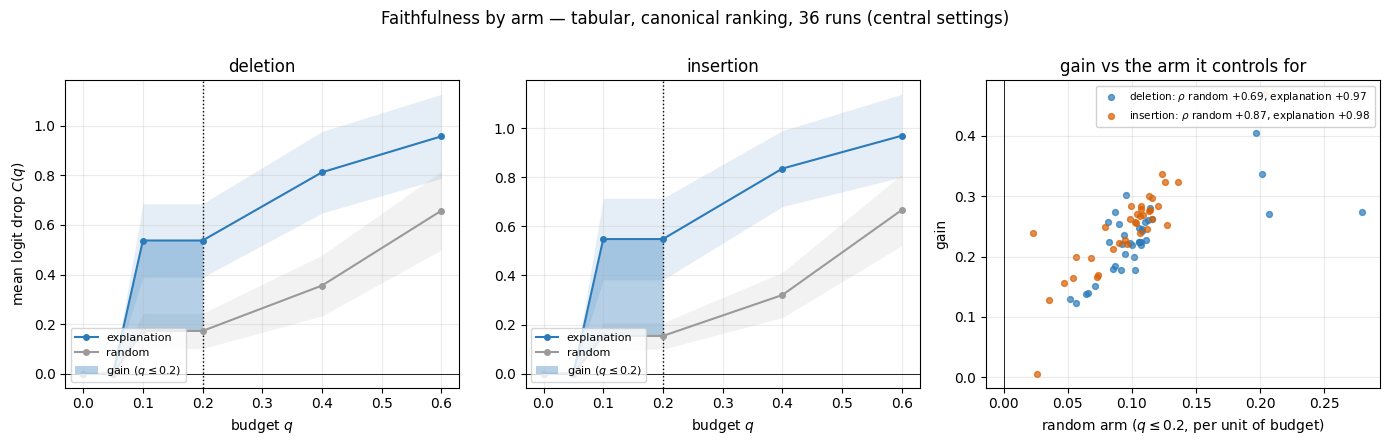

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.473,0.180,0.293,0.286,0.071,0.215
controlled_fusion,0.366,0.108,0.258,0.421,0.123,0.298
fixed_scaling,0.283,0.091,0.192,0.324,0.092,0.232
learnable_scaling,0.263,0.080,0.183,0.300,0.082,0.217
loss_regularization,0.322,0.096,0.226,0.372,0.108,0.264
vanilla,0.307,0.092,0.216,0.352,0.101,0.251



canonical ranking — image
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


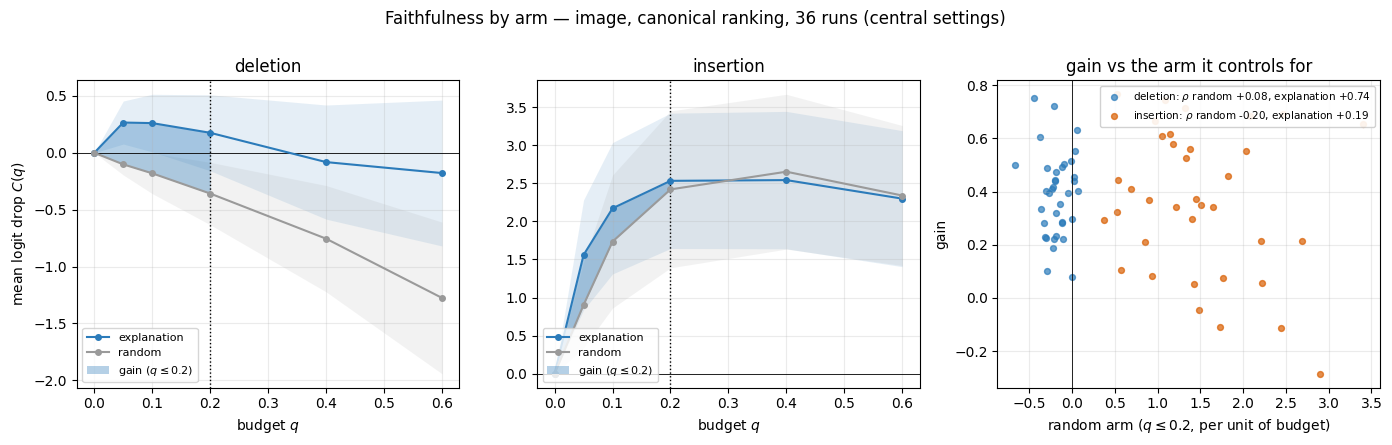

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.259,-0.208,0.468,1.906,1.418,0.488
controlled_fusion,0.326,-0.132,0.458,1.826,1.370,0.456
fixed_scaling,0.109,-0.185,0.294,1.897,1.659,0.238
learnable_scaling,0.227,-0.167,0.395,2.038,1.593,0.446
loss_regularization,0.102,-0.173,0.274,1.649,1.436,0.213
vanilla,0.225,-0.231,0.457,1.706,1.411,0.295



canonical ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


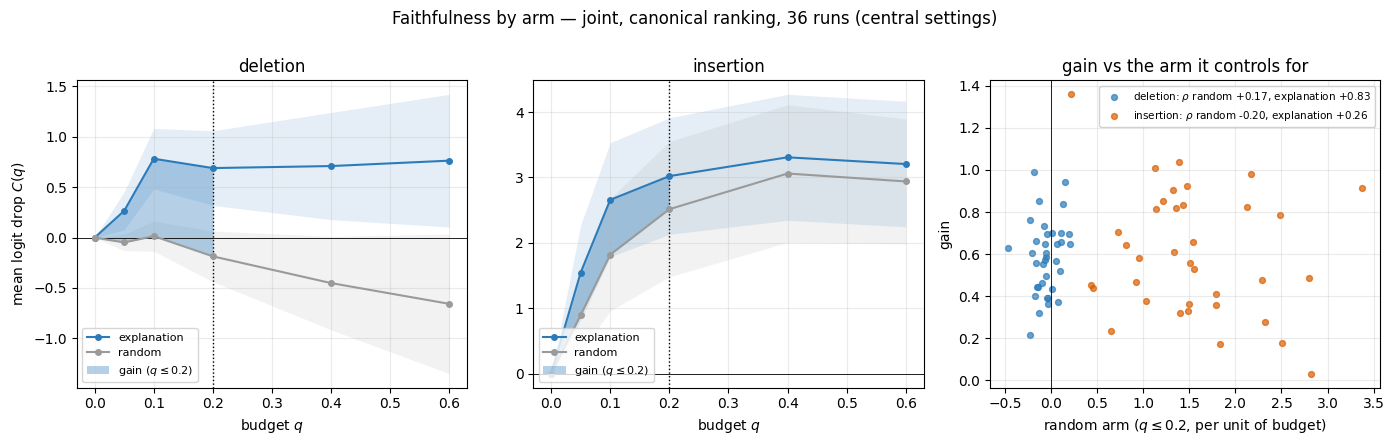

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.664,-0.031,0.695,1.944,1.306,0.638
controlled_fusion,0.691,-0.009,0.701,2.247,1.513,0.733
fixed_scaling,0.393,-0.071,0.463,2.221,1.700,0.521
learnable_scaling,0.491,-0.058,0.549,2.338,1.650,0.688
loss_regularization,0.424,-0.051,0.475,2.021,1.538,0.483
vanilla,0.533,-0.100,0.633,2.058,1.504,0.554



gradient ranking — tabular
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


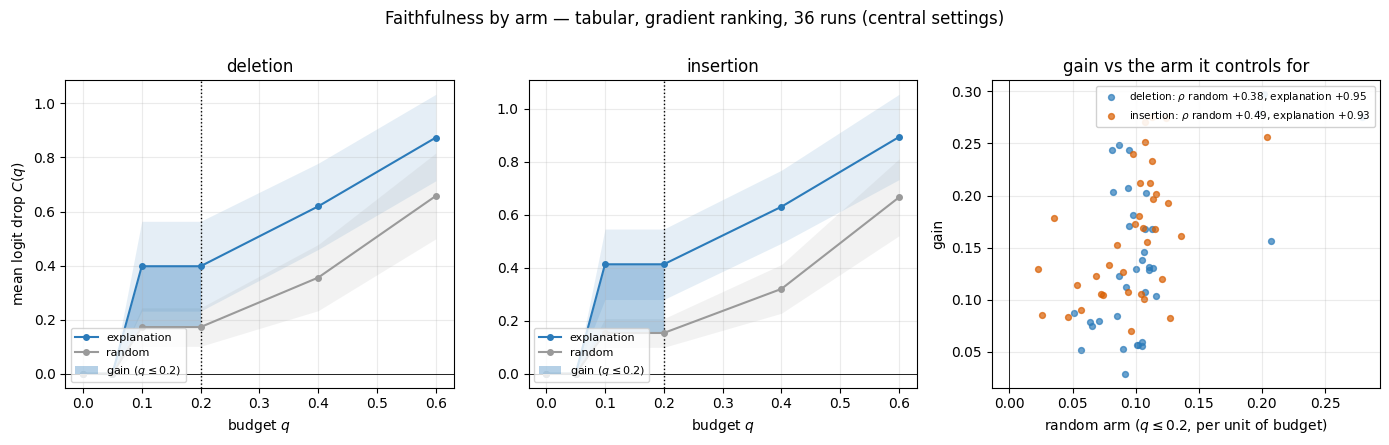

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.375,0.180,0.195,0.216,0.071,0.145
controlled_fusion,0.228,0.108,0.121,0.279,0.123,0.156
fixed_scaling,0.208,0.091,0.116,0.248,0.092,0.156
learnable_scaling,0.193,0.080,0.113,0.229,0.082,0.147
loss_regularization,0.247,0.096,0.151,0.294,0.108,0.185
vanilla,0.241,0.092,0.149,0.284,0.101,0.183



gradient ranking — joint
  [ablations] report figures: 12 unimodal endpoint runs excluded from the aggregate


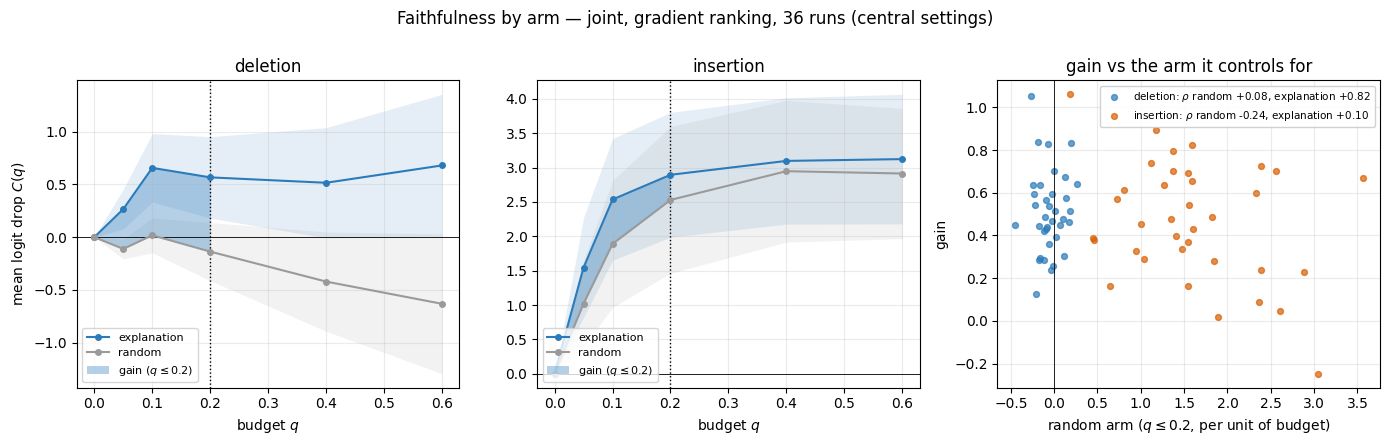

,del_exp,del_rand,del_gain,ins_exp,ins_rand,ins_gain
impl_name,,,,,,
adaptive_gating,0.622,-0.054,0.676,1.914,1.336,0.578
controlled_fusion,0.554,0.017,0.537,2.105,1.555,0.549
fixed_scaling,0.317,-0.077,0.394,2.145,1.797,0.347
learnable_scaling,0.420,-0.060,0.481,2.267,1.730,0.537
loss_regularization,0.348,-0.050,0.398,1.943,1.578,0.365
vanilla,0.466,-0.109,0.575,1.990,1.576,0.413


In [18]:
# @@REPORT_FIGURES@@ — the arm figures, the ones a table cannot carry (CPU, no checkpoint)
# Self-contained: paths and central settings come from the modules, so a fresh kernel is enough.
from isic24 import xai_faithfulness as xf, xai_figures as xfig

_ARM_COLS = ["del_exp", "del_rand", "del_gain", "ins_exp", "ins_rand", "ins_gain"]
for _src, _meths in xf.DEFAULT_METHODS.items():
    if _src == "aligned_signed":       # a sign convention, not a second attributor
        continue
    for _meth in _meths:
        print(f"\n{_src} ranking — {_meth}")
        display(xfig.arms(source=_src, method=_meth)
                .groupby("impl_name")[_ARM_COLS].mean().round(3))

In [19]:
# @@LORE_SECTION@@ — aggregate the per-sample LORE CSVs SUBSET 3/3 wrote (CPU)
from isic24.run_ids import run_id_from_artifact

_lore_files = sorted(glob.glob(os.path.join(RUNS_PATH, "**", "xai", "lore_sa", "epoch*",
                                            "lore_sa_persample_*.csv"), recursive=True))
if not _lore_files:
    print("No `lore_sa` artifact yet: run `SUBSET 3/3`, which writes xai/lore_sa/.")
else:
    print(f"[LORE] {len(_lore_files)} runs from xai/lore_sa/")
    _master = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))
    _meta = {str(r.run_id): (r.impl_name, r.setting_tag, int(r.seed)) for _, r in _master.iterrows()}

    _rows, _unmatched = [], []
    for f in _lore_files:
        _rid = run_id_from_artifact(f)
        if _rid not in _meta:
            _unmatched.append(f"{_rid}   ({f})")
            continue
        d = pd.read_csv(f)
        d["run_id"] = _rid
        d["impl_name"], d["setting_tag"], d["seed"] = _meta[_rid]
        d["rng_protocol"] = "seeded-v2" if "rng_seed" in d.columns else "unseeded-v1"
        _rows.append(d)
    if _unmatched:
        raise RuntimeError("LORE artifacts absent from the canonical registry:\n  "
                           + "\n  ".join(_unmatched))

    L = pd.concat(_rows, ignore_index=True)
    L["covered"] = L["neigh_n_classes"] >= 2
    L["rule_len_covered"] = L["rule_len"].where(L["covered"])
    L["fid_cv_bacc_covered"] = L["fid_cv_bacc"].where(L["covered"])
    L["legacy_unseeded"] = L["rng_protocol"] == "unseeded-v1"

    fam = L.groupby(["impl_name", "setting_tag"]).agg(
        n_run=("run_id", "nunique"),
        n_samples=("i", "size"),
        lore_coverage=("covered", "mean"),
        neigh_pos_rate=("neigh_pos_rate", "mean"),
        neigh_unique_frac=("neigh_unique_frac", "mean"),
        rule_len_covered=("rule_len_covered", "mean"),
        fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"),
    )
    fam["n_covered"] = L.groupby(["impl_name", "setting_tag"])["covered"].sum()
    fam["n_legacy_runs"] = (L[L.legacy_unseeded]
        .groupby(["impl_name", "setting_tag"])["run_id"].nunique()
        .reindex(fam.index, fill_value=0).astype(int))
    print("\nLORE explanation quality by family "
          "(`lore_coverage` = how far the tabular branch drives the decision)")
    _controls = np.array([xs.is_ablation(i, t) for i, t in fam.index])
    display(fam.loc[~_controls].round(3))
    print("Unimodal controls (excluded from inference)")
    display(fam.loc[_controls].round(3))

    cw = (L.groupby(["impl_name", "setting_tag", "true_label"])
            .agg(n=("i", "size"), lore_coverage=("covered", "mean"),
                 neigh_pos_rate=("neigh_pos_rate", "mean"),
                 rule_len_covered=("rule_len_covered", "mean"),
                 fid_cv_bacc_covered=("fid_cv_bacc_covered", "mean"))
            .unstack("true_label"))
    _class_names = ("No diabetic retinopathy", "Diabetic retinopathy")
    print(f"\nBy true class: 0 = {_class_names[0]}, 1 = {_class_names[1]}")
    display(cw.loc[fam.index[~_controls]].round(3))
    print("Unimodal controls (excluded from inference)")
    display(cw.loc[fam.index[_controls]].round(3))
    cw.reset_index().to_csv(
        os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family_class.csv"),
        index=False)

    print("\nWithin-setting class contrasts: paired seeds; unadjusted exploratory p-values")
    _run_coverage = (L.groupby(["impl_name", "setting_tag", "seed", "true_label"])
                     ["covered"].mean().unstack("true_label").reindex(columns=[0, 1]))
    _contrasts = []
    for (_impl, _tag), _g in _run_coverage.groupby(level=["impl_name", "setting_tag"]):
        if xs.is_ablation(_impl, _tag):
            continue
        _paired = _g.dropna()
        _res = xs.across_runs(_paired[0], _paired[1], *_class_names)
        _res["n_seeds"] = _res.pop("n_run")
        _contrasts.append(dict(impl_name=_impl, setting_tag=_tag,
                               coverage_negative=_paired[0].mean(),
                               coverage_positive=_paired[1].mean(), **_res))
    _lore_contrasts = pd.DataFrame(_contrasts)
    display(_lore_contrasts.set_index(["impl_name", "setting_tag"])[[
        "n_seeds", "n_informative", "n_ties", "coverage_negative", "coverage_positive",
        "diff_mean", "diff_median", "n_positive", "sign_p", "wilcoxon_p", "p_floor",
    ]].round(4))

    _out = os.path.join(RUNS_PATH, "_faithfulness", "lore_sa_quality_by_family.csv")
    fam.reset_index().to_csv(_out, index=False)
    print("wrote", _out)
    print("`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV "
          "summaries exclude mono-class neighbourhoods.")
    print("Both tables aggregate the run away, so they carry no provenance sidecar: the "
          "stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.")

[LORE] 132 runs from xai/lore_sa/

LORE explanation quality by family (`lore_coverage` = how far the tabular branch drives the decision)


n_run  n_samples  lore_coverage  \
impl_name           setting_tag                                    
adaptive_gating     base             6        360          0.861   
controlled_fusion   base             6        360          0.428   
fixed_scaling       a0p125           6        360          0.236   
                    a0p250           6        360          0.172   
                    a0p375           6        360          0.236   
                    a0p500           6        360          0.275   
                    a0p625           6        360          0.403   
                    a0p750           6        360          0.331   
                    a0p875           6        360          0.292   
learnable_scaling   init_a0p100      6        360          0.158   
                    init_a0p300      6        360          0.256   
                    init_a0p500      6        360          0.214   
                    init_a0p700      6        360          0.278   
                    init_a0p900      6        360          0.522   
loss_regularization lam0e+00         6        360          0.311   
                    lam1e-02         6        360          0.219   
                    lam1e-03         6        360          0.286   
                    lam1e-04         6        360          0.250   
                    lam1e-05         6        360          0.303   
vanilla             baseline         6        360          0.319   

                                 neigh_pos_rate  neigh_unique_frac  \
impl_name           setting_tag                                      
adaptive_gating     base                  0.419              0.582   
controlled_fusion   base                  0.349              0.568   
fixed_scaling       a0p125                0.317              0.561   
                    a0p250                0.293              0.558   
                    a0p375                0.306              0.561   
                    a0p500                0.320              0.561   
                    a0p625                0.363              0.568   
                    a0p750                0.336              0.564   
                    a0p875                0.323              0.562   
learnable_scaling   init_a0p100           0.301              0.559   
                    init_a0p300           0.343              0.562   
                    init_a0p500           0.308              0.560   
                    init_a0p700           0.324              0.562   
                    init_a0p900           0.376              0.571   
loss_regularization lam0e+00              0.340              0.563   
                    lam1e-02              0.287              0.560   
                    lam1e-03              0.293              0.563   
                    lam1e-04              0.300              0.561   
                    lam1e-05              0.325              0.563   
vanilla             baseline              0.329              0.562   

                                 rule_len_covered  fid_cv_bacc_covered  \
impl_name           setting_tag                                          
adaptive_gating     base                    2.435                0.961   
controlled_fusion   base                    2.883                0.962   
fixed_scaling       a0p125                  2.094                0.976   
                    a0p250                  2.081                0.971   
                    a0p375                  2.294                0.971   
                    a0p500                  2.404                0.974   
                    a0p625                  2.090                0.974   
                    a0p750                  2.513                0.972   
                    a0p875                  2.438                0.970   
learnable_scaling   init_a0p100             1.789                0.973   
                    init_a0p300             2.315                0.976   
                    init_a0p500  

Unimodal controls (excluded from inference)


n_run  n_samples  lore_coverage  neigh_pos_rate  \
impl_name     setting_tag                                                    
fixed_scaling a0p000           6        360            0.0           0.286   
              a1p000           6        360            1.0           0.521   

                           neigh_unique_frac  rule_len_covered  \
impl_name     setting_tag                                        
fixed_scaling a0p000                   0.553               NaN   
              a1p000                   0.576             4.367   

                           fid_cv_bacc_covered  n_covered  n_legacy_runs  
impl_name     setting_tag                                                 
fixed_scaling a0p000                       NaN          0              2  
              a1p000                     0.955        360              1


By true class: 0 = No diabetic retinopathy, 1 = Diabetic retinopathy


n      lore_coverage        neigh_pos_rate  \
true_label                         0    1             0      1              0   
impl_name           setting_tag                                                 
adaptive_gating     base         180  180         0.822  0.900          0.261   
controlled_fusion   base         180  180         0.272  0.583          0.090   
fixed_scaling       a0p125       180  180         0.083  0.389          0.032   
                    a0p250       180  180         0.033  0.311          0.010   
                    a0p375       180  180         0.078  0.394          0.024   
                    a0p500       180  180         0.139  0.411          0.042   
                    a0p625       180  180         0.300  0.506          0.081   
                    a0p750       180  180         0.222  0.439          0.065   
                    a0p875       180  180         0.172  0.411          0.038   
learnable_scaling   init_a0p100  180  180         0.033  0.283          0.011   
                    init_a0p300  180  180         0.111  0.400          0.034   
                    init_a0p500  180  180         0.111  0.317          0.031   
                    init_a0p700  180  180         0.139  0.417          0.045   
                    init_a0p900  180  180         0.483  0.561          0.128   
loss_regularization lam0e+00     180  180         0.183  0.439          0.057   
                    lam1e-02     180  180         0.056  0.383          0.017   
                    lam1e-03     180  180         0.128  0.444          0.033   
                    lam1e-04     180  180         0.078  0.422          0.020   
                    lam1e-05     180  180         0.228  0.378          0.063   
vanilla             baseline     180  180         0.183  0.456          0.055   

                                       rule_len_covered         \
true_label                           1                0      1   
impl_name           setting_tag                                  
adaptive_gating     base         0.577            2.000  2.833   
controlled_fusion   base         0.609            1.939  3.324   
fixed_scaling       a0p125       0.602            1.867  2.143   
                    a0p250       0.577            1.333  2.161   
                    a0p375       0.588            1.429  2.465   
                    a0p500       0.598            1.680  2.649   
                    a0p625       0.646            1.704  2.319   
                    a0p750       0.607            1.725  2.911   
                    a0p875       0.608            1.516  2.824   
learnable_scaling   init_a0p100  0.592            1.500  1.824   
                    init_a0p300  0.651            1.700  2.486   
                    init_a0p500  0.585            1.600  2.421   
                    init_a0p700  0.603            1.960  2.827   
                    init_a0p900  0.624            1.644  2.356   
loss_regularization lam0e+00     0.623            1.909  2.494   
                    lam1e-02     0.558            2.100  2.420   
                    lam1e-03     0.553            1.913  2.712   
                    lam1e-04     0.580            1.929  2.487   
                    lam1e-05     0.588            1.634  2.618   
vanilla             baseline     0.604            1.727  2.524   

                                fid_cv_bacc_covered         
true_label                                        0      1  
impl_name           setting_tag                             
adaptive_gating     base                      0.961  0.962  
controlled_fusion   base                      0.965  0.960  
fixed_scaling       a0p125                    0.974  0.976  
                    a0p250                    0.970  0.971  
                    a0p375                    0.969  0.971  
                    a0p500                    0.975  0.974  
                    a0p625                    0.974  0.974  
                    a0p750                

Unimodal controls (excluded from inference)


n      lore_coverage      neigh_pos_rate         \
true_label                   0    1             0    1              0      1   
impl_name     setting_tag                                                      
fixed_scaling a0p000       180  180           0.0  0.0          0.000  0.572   
              a1p000       180  180           1.0  1.0          0.501  0.540   

                          rule_len_covered        fid_cv_bacc_covered         
true_label                               0      1                   0      1  
impl_name     setting_tag                                                     
fixed_scaling a0p000                   NaN    NaN                 NaN    NaN  
              a1p000                 4.122  4.611               0.955  0.954


Within-setting class contrasts: paired seeds; unadjusted exploratory p-values


n_seeds  n_informative  n_ties  \
impl_name           setting_tag                                   
adaptive_gating     base               6              5       1   
controlled_fusion   base               6              6       0   
fixed_scaling       a0p125             6              6       0   
                    a0p250             6              6       0   
                    a0p375             6              6       0   
                    a0p500             6              6       0   
                    a0p625             6              5       1   
                    a0p750             6              6       0   
                    a0p875             6              6       0   
learnable_scaling   init_a0p100        6              6       0   
                    init_a0p300        6              6       0   
                    init_a0p500        6              6       0   
                    init_a0p700        6              6       0   
                    init_a0p900        6              6       0   
loss_regularization lam0e+00           6              6       0   
                    lam1e-02           6              6       0   
                    lam1e-03           6              6       0   
                    lam1e-04           6              6       0   
                    lam1e-05           6              6       0   
vanilla             baseline           6              6       0   

                                 coverage_negative  coverage_positive  \
impl_name           setting_tag                                         
adaptive_gating     base                    0.8222             0.9000   
controlled_fusion   base                    0.2722             0.5833   
fixed_scaling       a0p125                  0.0833             0.3889   
                    a0p250                  0.0333             0.3111   
                    a0p375                  0.0778             0.3944   
                    a0p500                  0.1389             0.4111   
                    a0p625                  0.3000             0.5056   
                    a0p750                  0.2222             0.4389   
                    a0p875                  0.1722             0.4111   
learnable_scaling   init_a0p100             0.0333             0.2833   
                    init_a0p300             0.1111             0.4000   
                    init_a0p500             0.1111             0.3167   
                    init_a0p700             0.1389             0.4167   
                    init_a0p900             0.4833             0.5611   
loss_regularization lam0e+00                0.1833             0.4389   
                    lam1e-02                0.0556             0.3833   
                    lam1e-03                0.1278             0.4444   
                    lam1e-04                0.0778             0.4222   
                    lam1e-05                0.2278             0.3778   
vanilla             baseline                0.1833             0.4556   

                                 diff_mean  diff_median  n_positive  sign_p  \
impl_name           setting_tag                                               
adaptive_gating     base            0.0778       0.1000           4  0.3750   
controlled_fusion   base            0.3111       0.3833           5  0.2188   
fixed_scaling       a0p125          0.3056       0.3000           6  0.0312   
                    a0p250          0.2778       0.2667           6  0.0312   
                    a0p375          0.3167       0.3167           6  0.0312   
                    a0p500          0.2722       0.2333           6  0.0312   
                    a0p625          0.2056       0.1500           5  0.0625   
                    a0p750          0.2167       0.3000           5  0.2188   
                    a0p875          0.2389       0.3167           5  0.2188   
learnable_scaling   init_a0p100     0.2500       0.2667           6  0.0312   
   

wrote /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain/runs/_faithfulness/lore_sa_quality_by_family.csv
`n_legacy_runs` exposes the accepted unseeded-v1 artifacts; all rule and CV summaries exclude mono-class neighbourhoods.
Both tables aggregate the run away, so they carry no provenance sidecar: the stamped version of the same numbers is what `xs.report` writes in @@SUBSET@@ 3/3.


In [ ]:
# @@CAM_OVERLAP@@ — do two families look in the same places more than two seeds do?
from isic24 import xai_metrics as xmet

_ov = xmet.cam_overlap_table(pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv")),
                             ART_PATH, central=xs.CENTRAL_SETTINGS,
                             out_dir=os.path.join(RUNS_PATH, "_faithfulness"))
display(_ov.groupby("pair_kind")[["iou_half", "iou_top"]].agg(["median", "mean", "count"]).round(3))
print("the counts above are PAIRS: this table describes, it does not test")

_contrast = pd.concat([xmet.seed_level_contrast(_ov, c, "cross_family", "seed_null").assign(iou=c)
                       for c in ("iou_half", "iou_top")], ignore_index=True)
print("\nCross-family against the seed null, with the SEED as the unit")
display(_contrast.set_index("iou").round(4))
print(f"{int(_contrast.n_seeds.max())} seeds put the floor at p = {_contrast.p_floor.max():.3f};")
print("positive diff = two FAMILIES overlap more than two seeds of one family do.")

In [20]:
# @@SHAPE@@ — explanation-shape metrics and stability, from the artifacts on disk
import pandas as pd, os
from isic24 import xai_metrics as xmet

_m = pd.read_csv(os.path.join(SUMMARIES_PATH, "master_results_rows.csv"))

_out = xs.report(_m, ART_PATH, kinds=(), central=CENTRAL_SETTINGS,
                 encoded_feature_names=encoded_feature_names, shape_top_k=CFG.shape_top_k)
_shape, _stab, _fam = _out["shape"], _out["stability"], _out["by_family"]
print(f"\n[shape] {len(_shape)} runs | {len(_stab)} pairs | "
      f"{int(_shape.branch_off.sum())} runs with the tabular branch off (metrics = NaN)")

print("\nStability@k by pair kind — the pair is the unit here, and this table describes")
display(_stab.pivot_table(index="impl_name", columns="pair_kind", values="stability_at_k",
                          aggfunc=["mean", "count"]).round(3))

_contrast = xmet.seed_level_contrast(_stab, "stability_at_k", "adjacent_param",
                                     "same_param_seed", by="impl_name")
print("\nThe same contrast with the SEED as the unit — this one tests")
display(_contrast.set_index("impl_name").round(4))
print("positive diff = one step of the knob moves the top-k features LESS than the seed does;")
print("Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.")
print("Families with a single setting have no adjacent-parameter arm and no contrast.")

print("\nall metrics side by side")
display(_fam.round(3))

[report] 3 files in /mnt/disk1/home/cgiovannoni/mod-attendance/artifacts/brset/plain/runs/_faithfulness
    xai_shape_metrics.csv
    xai_stability.csv
    xai_summary_by_family.csv

[shape] 132 runs | 384 pairs | 6 runs with the tabular branch off (metrics = NaN)

Stability@k by pair kind — the pair is the unit here, and this table describes


mean                          count  \
pair_kind           adjacent_param same_param_seed adjacent_param   
impl_name                                                           
adaptive_gating                NaN           0.592            NaN   
controlled_fusion              NaN           0.749            NaN   
fixed_scaling                0.861           0.770           36.0   
learnable_scaling            0.844           0.779           24.0   
loss_regularization          0.887           0.796           24.0   
vanilla                        NaN           0.800            NaN   

                                     
pair_kind           same_param_seed  
impl_name                            
adaptive_gating                15.0  
controlled_fusion              15.0  
fixed_scaling                 105.0  
learnable_scaling              75.0  
loss_regularization            75.0  
vanilla                        15.0

  [seed unit] no 'adjacent_param' arm, so no contrast: adaptive_gating, controlled_fusion, vanilla

The same contrast with the SEED as the unit — this one tests


,n_seeds,effect_mean,effect_sd,null_mean,null_sd,diff_mean,n_positive,sign_p,wilcoxon_p,p_floor
impl_name,,,,,,,,,,
fixed_scaling,6,0.8610,0.0455,0.7704,0.0318,0.0906,6,0.0312,0.0312,0.0312
learnable_scaling,6,0.8442,0.0590,0.7792,0.0288,0.0650,5,0.2188,0.0625,0.0312
loss_regularization,6,0.8866,0.0390,0.7956,0.0222,0.0910,6,0.0312,0.0312,0.0312


positive diff = one step of the knob moves the top-k features LESS than the seed does;
Tests use paired seed differences; zero differences are excluded and p_floor uses the informative count.
Families with a single setting have no adjacent-parameter arm and no contrast.

all metrics side by side


,n_runs,faith_target_q20,faith_posev_q20,lore_coverage,lore_rule_len,shape__shap_compactness,shape__shap_k90_sparsity,shape__shap_mass,shape__lore_rule_compactness,shape__agreement_shap_lore,shape__agreement_n_overlap,shape__lore_n,shape__lore_samples,shape__stability_adjacent,shape__stability_seed_null,shape__stability_effect
impl_name,,,,,,,,,,,,,,,,
adaptive_gating,6,0.394,0.383,0.861,2.421,0.599,0.963,8.436,0.733,0.334,60.0,60,1,NaN,0.592,NaN
controlled_fusion,6,0.361,0.354,0.428,2.749,0.579,0.959,6.740,0.698,0.155,60.0,60,1,NaN,0.749,NaN
fixed_scaling,6,0.260,0.252,0.275,2.150,0.605,0.964,4.384,0.728,0.107,60.0,60,1,0.861,0.770,-0.091
learnable_scaling,6,0.241,0.235,0.214,2.285,0.595,0.962,3.938,0.784,0.083,60.0,60,1,0.844,0.779,-0.065
loss_regularization,6,0.326,0.316,0.286,2.366,0.592,0.962,5.169,0.726,0.116,60.0,60,1,0.887,0.796,-0.091
vanilla,6,0.306,0.297,0.319,2.221,0.597,0.963,5.148,0.766,0.122,60.0,60,1,NaN,0.800,NaN
